In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# call file


In [3]:
df = pd.read_csv('train.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df. info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


# Descrie section


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


# spaces and duplicated values

In [6]:
df_clean = df.copy()
# remove spaces
df_clean.columns = df_clean.columns.str.strip()
df_clean.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [7]:
df_clean['Embarked'] = df_clean['Embarked'].str.strip()
df_clean['Embarked'] = df_clean['Embarked'].replace('', np.nan)
print(df_clean.duplicated().sum())

0


#missing value

In [8]:
df_clean.isna().sum().T


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


177 empty in age column ,687 cabain, embarked 2

# #1- Filling Embark column

In [9]:
# Filling Embark column

Repeted_in_Embarked = df_clean['Embarked'].mode()
print(Repeted_in_Embarked) # most repeted value is --> S
# fill emptey cells in embarked column with S
df_clean['Embarked'] = df_clean['Embarked'].fillna('S')
df_clean.isnull().sum().T

0    S
Name: Embarked, dtype: object


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


#2- Filling age column

In [10]:
# fill the emptey cell with medians
group_medians = df_clean.groupby(['Pclass', 'Sex'])['Age'].transform('median')
df_clean['Age'] = df_clean['Age'].fillna(group_medians)
print(group_medians.T)

0      25.0
1      35.0
2      21.5
3      35.0
4      25.0
       ... 
886    30.0
887    35.0
888    21.5
889    40.0
890    25.0
Name: Age, Length: 891, dtype: float64


In [11]:
df_clean.isnull().sum().T

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


#3- Cabin column

In [12]:
df_clean['Cabin'].isnull().sum()

np.int64(687)

In [13]:
#df_clean['Has_Cabin'] = df_clean['Cabin'].notnull().astype(int)
#df_clean = df_clean.drop(columns=['Cabin'])
print(df_clean.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


#Outliers


In [14]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,891.0,29.112424,13.304424,0.42,21.5000,26.0000,36.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [15]:
Q1 = df_clean['Fare'].quantile(0.25)
Q3 = df_clean['Fare'].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + (1.5 * IQR)
outliers = df_clean[df_clean['Fare'] > upper_bound]
print(outliers)

     PassengerId  Survived  Pclass  \
1              2         1       1   
27            28         0       1   
31            32         1       1   
34            35         0       1   
52            53         1       1   
..           ...       ...     ...   
846          847         0       3   
849          850         1       1   
856          857         1       1   
863          864         0       3   
879          880         1       1   

                                                  Name     Sex   Age  SibSp  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
27                      Fortune, Mr. Charles Alexander    male  19.0      3   
31      Spencer, Mrs. William Augustus (Marie Eugenie)  female  35.0      1   
34                             Meyer, Mr. Edgar Joseph    male  28.0      1   
52            Harper, Mrs. Henry Sleeper (Myna Haxtun)  female  49.0      1   
..                                                 ...     ...   ... 

there are 116 out liers

# Feature Engineering

In [16]:
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1 # new column to know family size of every passenger
df_clean['IsAlone'] = (df_clean['FamilySize'] == 1).astype(int) # check if passenger alone or not if alone = 1,  if not =0
print(df_clean.groupby('IsAlone')['Survived'].mean())

IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64


In [17]:
df_clean.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,NaN,Q,1,1
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,1,1
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,5,0
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,3,0
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,2,0


In [18]:
# make new column for children whom > 16
df_clean['Is Child'] = (df_clean['Age']< 16).astype(int)
df_clean['Is Child'].sum()
#

np.int64(83)

number of childern in Titanic is 83 from 891 whose there age under 16 ys




# Visualization (Categorical with countplot)



#-Number of servived people and there sex

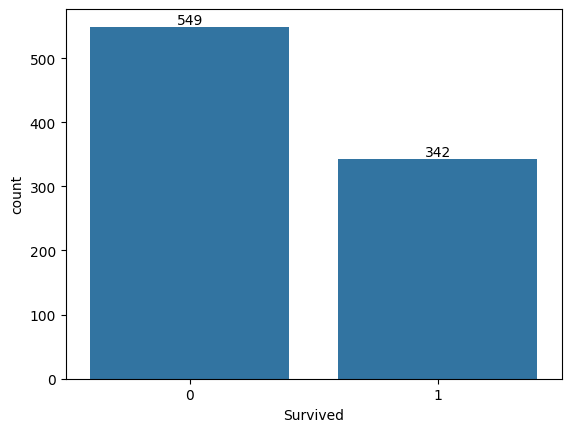

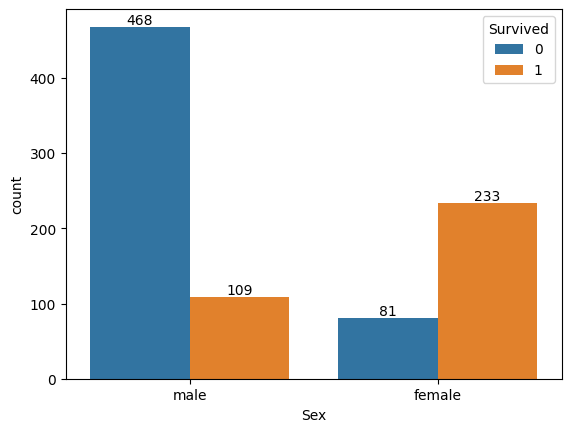

In [19]:
ax= sns.countplot(data=df_clean, x='Survived')
for container in ax.containers:
    ax.bar_label(container)
plt.show()

ax = sns.countplot(data=df_clean, x='Sex', hue='Survived')
for container in ax.containers:
    ax.bar_label(container)
plt.show()

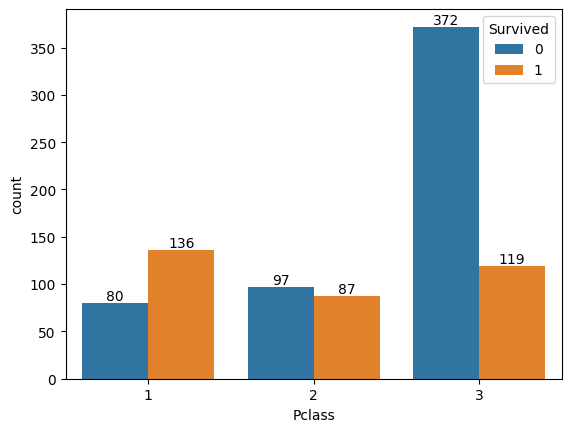

In [20]:
ax = sns.countplot(data=df_clean, x='Pclass', hue='Survived')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [21]:
df_clean.head(30)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize,IsAlone,Is Child
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,2,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,0,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,1,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,0,0
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,1,1,0
5,6,0,3,"Moran, Mr. James",male,25.0,0,0,330877,8.4583,NaN,Q,1,1,0
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,1,1,0
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,5,0,1
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,3,0,0
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,2,0,1


#  -Histogram: Age Distribution by Survival

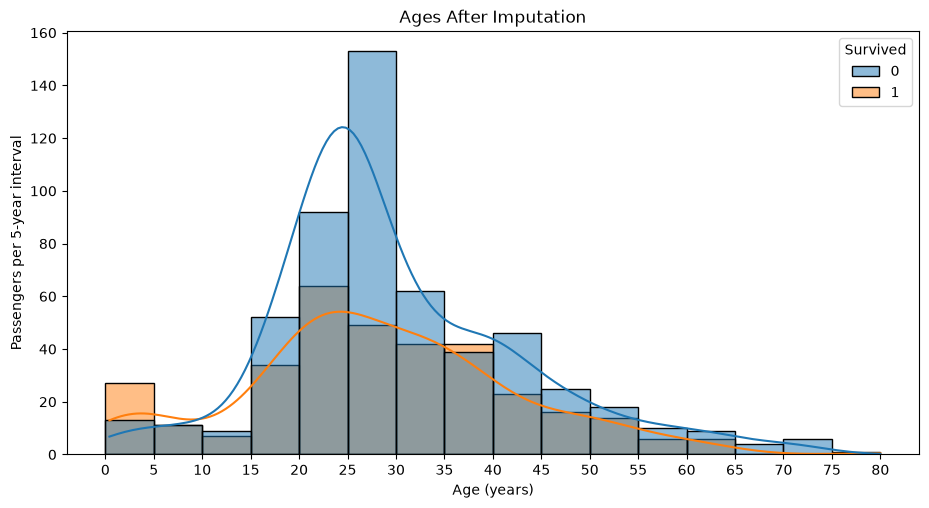

In [21]:
# Ages after group-median imputation
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(data=df_clean, x='Age', hue='Survived', binwidth=5,
             binrange=(0, 80), multiple='layer', alpha=0.5, kde=True, ax=ax)
ax.set_title('Ages After Imputation')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Passengers per 5-year interval')
ax.set_xticks(range(0, 85, 5))
plt.show()


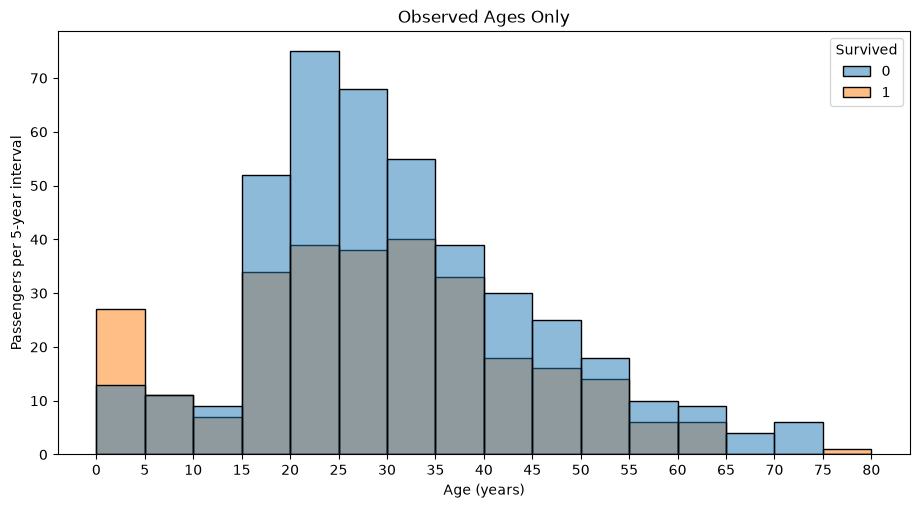

In [22]:
# Compare using only ages recorded in the raw data
observed_age = df_clean.loc[df['Age'].notna()]
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.histplot(data=observed_age, x='Age', hue='Survived', binwidth=5,
             binrange=(0, 80), multiple='layer', alpha=0.5, ax=ax)
ax.set_title('Observed Ages Only')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Passengers per 5-year interval')
ax.set_xticks(range(0, 85, 5))
plt.show()


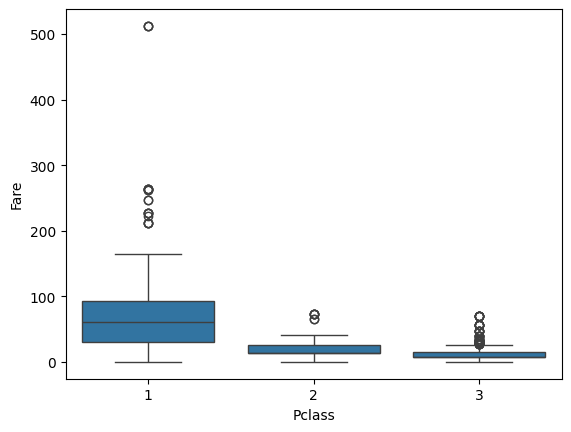

In [24]:
sns.boxplot(data=df_clean, x='Pclass', y='Fare')
plt.show()



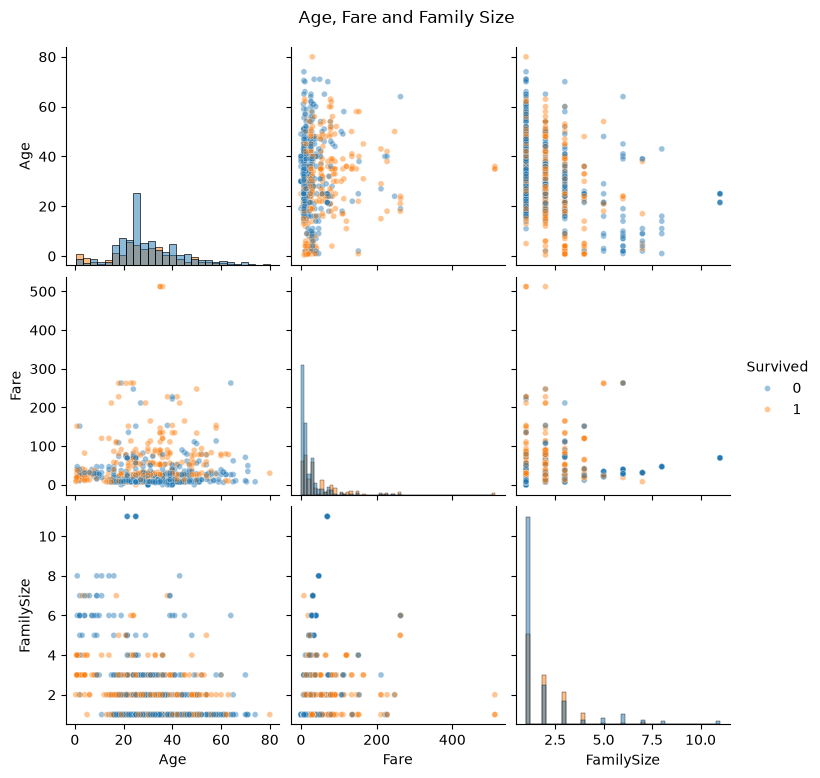

In [24]:
# Focus on age, fare and family size
g = sns.pairplot(df_clean, vars=['Age', 'Fare', 'FamilySize'],
                 hue='Survived', diag_kind='hist', height=2.5,
                 plot_kws={'alpha': 0.45, 's': 18})
g.figure.suptitle('Age, Fare and Family Size', y=1.03)
plt.show()


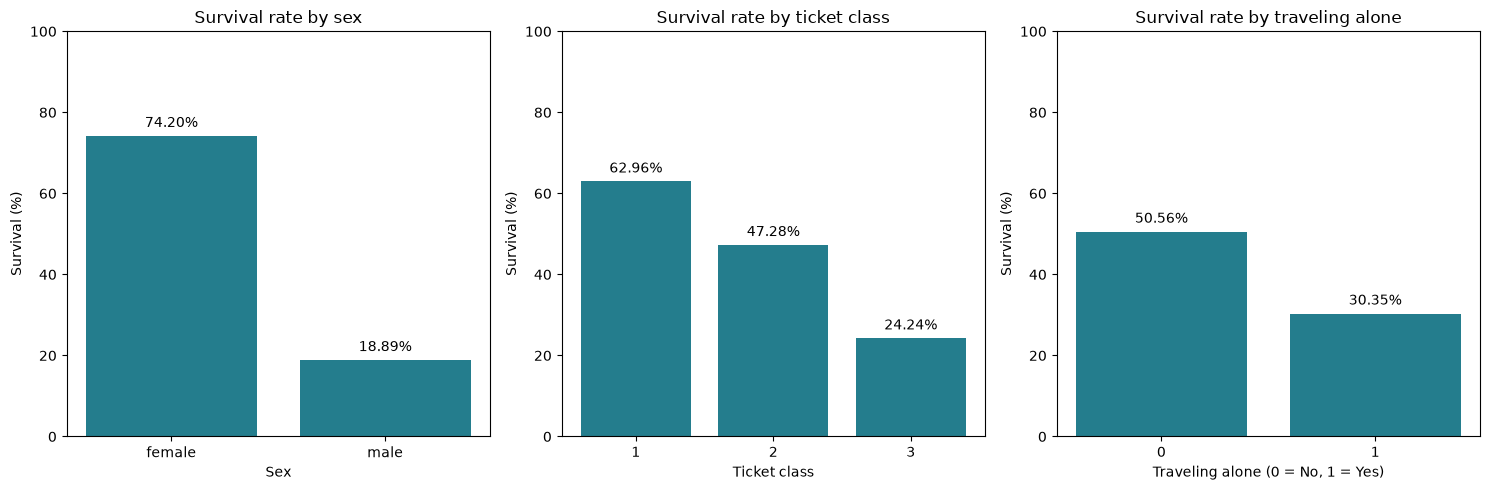

In [25]:
# Survival percentage by sex, passenger class and traveling alone
from pathlib import Path

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

columns = ['Sex', 'Pclass', 'IsAlone']
titles = ['Survival rate by sex', 'Survival rate by ticket class', 'Survival rate by traveling alone']
xlabels = ['Sex', 'Ticket class', 'Traveling alone (0 = No, 1 = Yes)']

for ax, column, title, xlabel in zip(axes, columns, titles, xlabels):
    survival_percent = df_clean.groupby(column)['Survived'].mean() * 100
    bars = ax.bar(survival_percent.index.astype(str), survival_percent.values, color='#247d8d')
    ax.bar_label(bars, labels=[f'{value:.2f}%' for value in survival_percent.values], padding=4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Survival (%)')
    ax.set_ylim(0, 100)

plt.tight_layout()
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/08_survival_rates.png', dpi=220, bbox_inches='tight')
plt.show()